# 05.01 — Ile odczytów mieszczą głowy attention?

**Rachunek na tablicy i ćwiczenie w NumPy · około 40 minut**

Cztery pozycje $A,B,C,D$ przechowują cztery niezależne znaki $b_i\in\{-1,1\}$. Zapytanie ma odzyskać wartości z pierwszych $k$ pozycji jednocześnie. W [karcie przejścia od RNN](../4_CNN_RNN/Most_MLP_CNN_RNN_attention.md) widzieliśmy już, jak jedna głowa miesza wartości. Teraz obserwujemy, co zmienia dodanie drugiego i czwartego zestawu wag softmax.

**Zacznij od hipotezy.** Co zyskujemy, jeśli jedna głowa kieruje uwagę na $A$, a druga na $B$? Co się stanie, jeśli obie wybiorą $A$?

Po ćwiczeniu potrafisz rozpisać Q, K i V, odczytać mapy głów, złożyć ich wyniki i wyjaśnić, skąd wynika ograniczenie badanego odczytu.

## 1. Jedno zapytanie i jedna głowa

Wyobraź sobie cztery kartki z adresami $A,B,C,D$. Klucze $K$ odpowiadają adresom, zapytanie $q$ wskazuje szukany adres, a wartości $V$ zawierają zapisane znaki. Po projekcjach $q$ jest wektorem długości $d_h$, a macierze $K,V$ mają kształt $4\times d_h$. W naszym ćwiczeniu znak zajmuje pierwszą współrzędną $v_i$. Pozostałe współrzędne są zerami.

$$
s_i=\frac{q\cdot k_i}{\sqrt{d_h}},\qquad
\alpha_i=\frac{\exp(s_i)}{\sum_{j=1}^4\exp(s_j)},\qquad
z=\sum_{i=1}^4\alpha_i v_i.
$$

Ustawiamy cztery ortogonalne klucze $k_i=e_i$. Dla zapytania $q=\sqrt{d_h}\log(9)e_A$ wyniki dopasowania to $(\log 9,0,0,0)$. Wykładniki dają $(9,1,1,1)$, a po podzieleniu przez 12 otrzymujemy

$$
\alpha_A=\frac{1}{12}(9,1,1,1).
$$

W pierwszym rachunku używamy dwóch znaków i ustawiamy niewykorzystywane wartości na zero: $b=(1,-1,0,0)$. Wtedy pierwsza współrzędna wyjścia wynosi $9/12-1/12=2/3$. Jeżeli druga głowa zada pytanie o $B$, uzyska $\alpha_B=(1,9,1,1)/12$ i pierwszą współrzędną $1/12-9/12=-2/3$.

Każda mapa zależy tu wyłącznie od zadanego zapytania i kluczy. Podmiana znaku zmienia $V$ oraz wynik $z$ przy tych samych wagach $\alpha$. W uczonej warstwie $Q,K,V$ powstają z wejścia przez projekcje. Głowy mogą nauczyć się odczytywać różne sygnały.

In [1]:
import itertools

import matplotlib.pyplot as plt
import numpy as np

D_MODEL = 16
ROLES = ("A", "B", "C", "D")
N_ROLES = len(ROLES)


def attention(query, key, value):
    scores = query @ np.swapaxes(key, -1, -2) / np.sqrt(key.shape[-1])
    weights = np.exp(scores - scores.max(axis=-1, keepdims=True))
    weights /= weights.sum(axis=-1, keepdims=True)
    return weights @ value, weights


def route_readout(bits, destinations):
    heads = len(destinations)
    if not heads or D_MODEL % heads or D_MODEL // heads < N_ROLES:
        raise ValueError("W tym przykładzie dostępne są 1, 2 lub 4 głowy.")
    head_dim = D_MODEL // heads
    key = np.zeros((heads, N_ROLES, head_dim))
    key[:, :, :N_ROLES] = np.eye(N_ROLES)

    query = np.zeros((heads, 1, head_dim))
    query[np.arange(heads), 0, destinations] = np.sqrt(head_dim) * np.log(9)

    value = np.zeros((len(bits), heads, N_ROLES, head_dim))
    value[..., 0] = bits[:, None, :]
    z, weights = attention(query, key, value)
    return z[:, :, 0, :].reshape(len(bits), D_MODEL), weights[:, 0, :]


board = np.array([[1.0, -1.0, 0.0, 0.0]])
z_board, weights_board = route_readout(board, (0, 1))
print("Mapa attention dla dwóch głów\n", np.round(weights_board, 4), sep="")
print("Pierwsza współrzędna z każdej głowy", np.round(z_board[0, [0, 8]], 4))

Mapa attention dla dwóch głów
[[0.75   0.0833 0.0833 0.0833]
 [0.0833 0.75   0.0833 0.0833]]
Pierwsza współrzędna z każdej głowy [ 0.6667 -0.6667]


## 2. Co zmienia dodanie głów?

Każda głowa dostaje **po jednym wektorze zapytania dla tej samej pozycji**, a łączna szerokość reprezentacji pozostaje stała i wynosi $d_{\text{model}}=16$. Rozdzielamy współrzędne między $H$ głów. Każda liczy własny softmax, po czym sklejamy wyniki głów. W demonstracji projekcja wyjściowa $W_O$ jest identycznością.

| Głowy $H$ | Szerokość głowy $d_h$ | Dominujące adresy |
| ---: | ---: | --- |
| 1 | 16 | $A$ |
| 2 | 8 | $A$, $B$ |
| 4 | 4 | $A$, $B$, $C$, $D$ |

Badamy trzy zadania. Gdy $k=1$, odzyskujemy znak $A$. Gdy $k=2$, odzyskujemy niezależnie $A$ i $B$. Gdy $k=4$, odzyskujemy wszystkie cztery znaki. W każdym zadaniu pierwsze $k$ pozycji przyjmuje wszystkie $2^k$ kombinacji znaków, a pozostałe wartości ustawiamy na zero. Oceniamy **średni błąd kwadratowy na znak**, przed jakimkolwiek progowaniem.

W tym przykładzie każda głowa niesie jedną liczbę zależną od znaków, więc sklejony odczyt ma postać $z=Mb$, gdzie $M$ ma $k$ kolumn. Do odzyskania $b$ użyjemy odczytu liniowego $D z$. Najlepsze $D$ w sensie średniego błędu kwadratowego otrzymujemy przez pseudoodwrotność $M^+$. To rachunek po wszystkich możliwych wejściach tego zadania.

### Dwie liczby wystarczą, jeśli niosą różne informacje

Dla $k=2$ i dwóch głów niezerowa część $M$ to

$$
M_{\mathrm{aktywna}}
=\frac{1}{12}
\begin{pmatrix}
9&1\\
1&9
\end{pmatrix}.
$$

Po sklejeniu niezerowe wyniki dwóch głów oznaczamy jako $u_A$ i $u_B$. Z równań $12u_A=9b_A+b_B$ i $12u_B=b_A+9b_B$ otrzymujemy

$$
b_A=\frac{12}{80}(9u_A-u_B),\qquad
b_B=\frac{12}{80}(9u_B-u_A).
$$

Dla $u_A=2/3$ i $u_B=-2/3$ daje to $b_A=1$ i $b_B=-1$. Z jedną głową zostałby tylko wiersz $(9,1)/12$. Taki odczyt ma rząd 1, więc pojedyncza liczba nie wystarczy do **liniowego** odzyskania obu współrzędnych.

Dla niezależnych, jednakowo prawdopodobnych znaków $\mathbb E[bb^{\mathsf T}]=I_k$. Błąd dla pary wejście–odczyt to $(DM-I_k)b$. Po uśrednieniu kwadratów po wszystkich układach oraz wszystkich $k$ znakach otrzymujemy

$$
\operatorname{MSE}
=\frac{1}{k}\,\mathbb E\left[\left\|(DM-I_k)b\right\|_2^2\right]
=\frac{1}{k}\left\|DM-I_k\right\|_F^2.
$$

Najlepsze $DM=M^+M$ jest rzutem na przestrzeń rozpiętą przez wiersze $M$. Jeśli $r=\operatorname{rank}(M)$, rzut zachowuje $r$ kierunków i gubi $k-r$. Stąd minimalny liniowy MSE wynosi $(k-r)/k$. Przykładowo dla czterech znaków i dwóch niezależnych wierszy zostaje $(4-2)/4=0{,}50$.

In [2]:
def exact_task(k):
    signs = np.array(list(itertools.product((-1.0, 1.0), repeat=k)))
    values = np.zeros((len(signs), N_ROLES))
    values[:, :k] = signs
    return values, signs


def measure(k, destinations):
    values, expected = exact_task(k)
    features, weights = route_readout(values, destinations)
    head_dim = D_MODEL // len(destinations)
    operator = np.zeros((D_MODEL, k))
    operator[::head_dim] = weights[:, :k]

    decoder = np.linalg.pinv(operator)
    recovered = features @ decoder.T
    rank = np.linalg.matrix_rank(operator)
    mse = np.mean((recovered - expected)**2)
    return mse, rank, weights


tasks = (1, 2, 4)
head_counts = (1, 2, 4)
results = {(k, h): measure(k, tuple(range(h))) for k in tasks for h in head_counts}
mse = np.array([[results[k, h][0] for h in head_counts] for k in tasks])

print("Zadanie        1 głowa    2 głowy    4 głowy")
for k, errors in zip(tasks, mse):
    label = "1 znak" if k == 1 else f"{k} znaki"
    print(f"{label:12s}" + "    ".join(f"{e:7.2f}" for e in errors))
repeated_mse, repeated_rank, _ = measure(4, (0, 1, 2, 2))
print("Cztery głowy z jedną powtórzoną trasą | rząd", repeated_rank,
      "| MSE z odczytu", round(repeated_mse, 2), "| MSE ze wzoru", (4 - repeated_rank) / 4)

Zadanie        1 głowa    2 głowy    4 głowy
1 znak         0.00       0.00       0.00
2 znaki        0.50       0.00       0.00
4 znaki        0.75       0.50       0.00
Cztery głowy z jedną powtórzoną trasą | rząd 3 | MSE z odczytu 0.25 | MSE ze wzoru 0.25


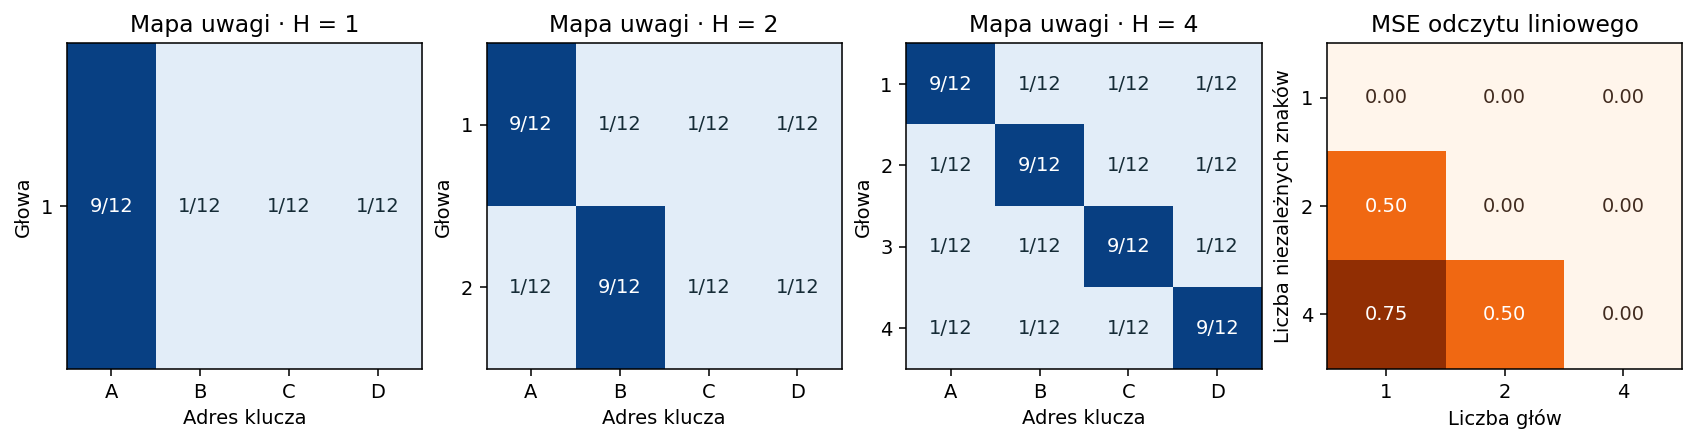

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.05), layout="constrained")

for h, ax in zip(head_counts, axes[:-1]):
    weights = results[4, h][2]
    ax.imshow(weights, vmin=0, vmax=.8, cmap="Blues", aspect="auto")
    ax.set(xticks=range(N_ROLES), xticklabels=ROLES, yticks=range(h),
           yticklabels=range(1, h+1), xlabel="Adres klucza", ylabel="Głowa",
           title=f"Mapa uwagi · H = {h}")
    for i, row in enumerate(weights):
        for j, v in enumerate(row):
            ax.text(j, i, f"{round(12 * v)}/12", ha="center", va="center",
                    color="white" if v > .45 else "#162c37")

ax = axes[-1]
ax.imshow(mse, vmin=0, vmax=.8, cmap="Oranges", aspect="auto")
ax.set(xticks=range(3), xticklabels=head_counts, yticks=range(3), yticklabels=tasks,
       xlabel="Liczba głów", ylabel="Liczba niezależnych znaków", title="MSE odczytu liniowego")
for i, row in enumerate(mse):
    for j, v in enumerate(row):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                color="white" if v > .45 else "#412b1f")
plt.show()

## 3. Jak przeczytać wynik?

Przy czterech znakach jedna głowa zostawia średni błąd kwadratowy $0{,}75$, dwie $0{,}50$, a cztery pozwalają odzyskać wszystkie znaki dokładnie. Gdy czwarta głowa powtarza kierunek trzeciej, rząd spada do trzech i MSE rośnie do $0{,}25$. Ważna jest liczba niezależnych mieszanin, które faktycznie trafiają do odczytu.

**Analogia do tekstu.** Jeden token może potrzebować dwóch niezależnych wskazówek, np. odczytać osobę i miejsce z różnych fragmentów zdania. Dwie różne mapy mogą pobrać te informacje równolegle. W demonstracji trasy są zadane. W trenowanym modelu role głów zależą m.in. od danych, celu i przebiegu treningu. Sama mapa pokazuje wagi sumowania $V$. Wpływ głowy na predykcję można sprawdzić, zmieniając jej wyjście i ponownie mierząc wynik modelu.

## 4. Co zmienia wynik przy jednej głowie?

Trzymamy szerokość $d_{\mathrm{model}}=16$ i sprawdzamy trzy warianty względem przypadku $H=1$.

1. **Bogatsze $V$ przy jednym zapytaniu.** Wpisujemy znak z adresu $i$ we współrzędną $i$ wektora $v_i$. Zachowujemy zapytanie o $A$ i jego wagi $(9,1,1,1)/12$. Cztery pierwsze współrzędne wyniku to $(9b_A,b_B,b_C,b_D)/12$. Każdy znak odzyskujemy, dzieląc jego współrzędną przez odpowiadającą wagę.
2. **Cztery zapytania przy tym samym $V$.** Zachowujemy jedną informacyjną współrzędną wartości. Każde zapytanie preferuje inny adres. Otrzymujemy cztery wiersze mapy i cztery wyjścia. Odczyt korzysta teraz z wyników czterech pozycji zamiast z jednej.
3. **Odczyt nieliniowy przy jednym zapytaniu i skalarnym wyniku.** Dla $k=2$ wynik $(9b_A+b_B)/12$ przyjmuje cztery różne wartości $-10/12,-8/12,8/12,10/12$. Można przypisać do nich cztery pary znaków i odzyskać je przez wyszukanie w tabeli. Ten przypadek odróżnia ograniczenie liniowego dekodera od samej rozróżnialności skończonego zbioru wejść.

In [4]:
values, expected = exact_task(4)
key = np.eye(N_ROLES, D_MODEL)

# Jedna głowa, jedno zapytanie, znak w osobnej współrzędnej wartości.
rich_values = values[:, :, None] * key
query = np.sqrt(D_MODEL) * np.log(9) * key
pooled, rich_weights = attention(query[:1], key, rich_values)

# Jedna głowa, znak w pierwszej współrzędnej, cztery zapytania.
scalar_value = np.zeros_like(rich_values)
scalar_value[..., 0] = values
routed, weights = attention(query, key, scalar_value)
recovered = routed[..., 0] @ np.linalg.pinv(weights).T
rich_recovered = pooled[:, 0, :N_ROLES] / rich_weights
print("Maksymalny błąd odzyskania, bogatsze V:", np.abs(rich_recovered - expected).max().round(12))
print("Maksymalny błąd odzyskania, cztery zapytania:", np.abs(recovered - expected).max().round(12))

# Przy k=2 każdy możliwy wynik wskazuje inną parę.
values_two, expected_two = exact_task(2)
encoded, _ = route_readout(values_two, (0,))
for scalar, pair in zip(encoded[:, 0], expected_two.astype(int)):
    print(f"{round(12 * scalar):3d}/12 → {tuple(pair.tolist())}")

Maksymalny błąd odzyskania, bogatsze V: 0.0
Maksymalny błąd odzyskania, cztery zapytania: 0.0
-10/12 → (-1, -1)
 -8/12 → (-1, 1)
  8/12 → (1, -1)
 10/12 → (1, 1)


## 5. Zadanie dla studenta

1. Ustaw trasy czterech głów na $(A,A,B,B)$. Oblicz rząd macierzy odczytu i przewidź MSE dla $k=4$. Sprawdź przez `measure(4, (0, 0, 1, 1))` i porównaj z `measure(4, (0, 1, 2, 3))`. Funkcja zwraca kolejno MSE, rząd i mapę uwagi.
2. Dla dwóch głów policz na kartce wyjścia, gdy $(b_A,b_B)=(-1,1)$. Usuń głowę $B$ i wskaż niezerowy kierunek $(\Delta b_A,\Delta b_B)$, którego pozostała głowa nie rozróżnia na $\mathbb R^2$.
3. Zaproponuj trenowane porównanie $H=1,2,4$. Ustal wspólne dane, szerokość modelu, liczbę warstw i budżet treningu. Mierz dokładność jednoczesnego odzyskania całego zestawu i powtórz dla kilku seedów. Wyłączenie głowy po treningu pozwala zadać dodatkowe pytanie o jej wkład w konkretnym modelu.

**Kontrola odpowiedzi.** Pierwsze trasy mają rząd 2 i MSE $0{,}5$. Dla pary $(-1,1)$ odczyty wynoszą $-2/3$ i $2/3$. Z pełnej macierzy odzyskujemy oba znaki wzorami z sekcji 2. Dla głowy $A$ kierunek $(1,-9)$ znika, ponieważ $9\cdot 1+1\cdot(-9)=0$. Ta zależność dotyczy wektorów rzeczywistych. Na czterech wejściach binarnych nadal da się użyć tabeli z sekcji 4.

W standardowym wariancie projekcji, przy ustalonym $d_{\text{model}}$ i $Hd_h=d_{\text{model}}$, cztery gęste macierze $W_Q,W_K,W_V,W_O$ bez biasów mają razem $4d_{\text{model}}^2$ parametrów dla każdej z tych liczb głów. Zmienia się organizacja odczytu i szerokość każdej głowy. W naszym rachunku macierze Q, K i V podajemy wprost. Wynik dotyczy tej kontrolowanej konstrukcji.

**Następne ćwiczenie.** [Blok Transformera](Ch05_02_blok_transformera.ipynb) pokazuje, gdzie trafia sklejony wynik głów i jak maski ograniczają dostęp do pozycji. W osobnym pakiecie attention można wcześniej wykonać ręczne QKV oraz trening małej głowy.